In [1]:
import sqlite3
import pandas as pd

In [19]:
df = pd.read_csv("../dataset/churn_data.csv")

In [20]:
conn = sqlite3.connect("churn.db")

In [23]:
df.to_sql("customers", conn, if_exists="replace", index=False)

print("Data inserted into SQL table!")

Data inserted into SQL table!


In [24]:
query = "SELECT * FROM customers LIMIT 5"
result = pd.read_sql(query, conn)

print(result)

   CustomerID  Age  Gender  Tenure  MonthlyCharges        Contract  \
0           1   56  Female      68          147.58        Two year   
1           2   69    Male      32           22.54  Month-to-month   
2           3   46  Female      10           52.47        One year   
3           4   32    Male      22          109.67  Month-to-month   
4           5   60  Female      54          130.98  Month-to-month   

      PaymentMethod  TotalCharges Churn  
0     Bank transfer      10052.03    No  
1      Mailed check        686.78    No  
2  Electronic check        537.88    No  
3      Mailed check       2390.04   Yes  
4       Credit card       7081.28    No  


Total customers by contract type

In [25]:
query = """
SELECT Contract, COUNT(*) AS total_customers
FROM customers
GROUP BY Contract
"""
pd.read_sql(query, conn)

,Contract,total_customers
0,Month-to-month,54915
1,One year,25261
2,Two year,19824


Churn count

In [26]:
query = """
SELECT Churn, COUNT(*) AS count
FROM customers
GROUP BY Churn
"""
pd.read_sql(query,conn)

,Churn,count
0,No,66856
1,Yes,33144


avg monthly charges by churn

In [27]:
query = """
SELECT Churn, AVG(MonthlyCharges) AS avg_charges
FROM customers
GROUP BY Churn
"""
pd.read_sql(query, conn)

,Churn,avg_charges
0,No,72.845838
1,Yes,94.355298


In [28]:
query = """
SELECT Churn, AVG(tenure) AS avg_tenure
FROM customers
GROUP BY Churn
"""
pd.read_sql(query, conn)

,Churn,avg_tenure
0,No,39.321796
1,Yes,30.889784


In [33]:
query = """
SELECT Contract, COUNT(*) AS total_customers
FROM customers
GROUP BY Contract
"""
pd.read_sql(query, conn)

,Contract,total_customers
0,Month-to-month,54915
1,One year,25261
2,Two year,19824


In [34]:
contract_data = pd.read_sql(query, conn)
print(contract_data)

         Contract  total_customers
0  Month-to-month            54915
1        One year            25261
2        Two year            19824


<Axes: xlabel='Contract'>

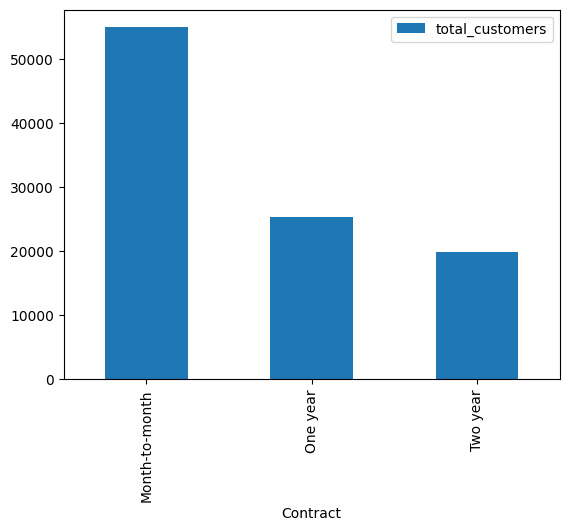

In [35]:
contract_data.plot(kind='bar', x='Contract', y='total_customers')